# ReZonate: exploration notebook

Use this to explore embeddings, check your taste modes, listen to a batch and rate it.
The fast rating loop is the CLI (`rezonate rate`); ratings made here are stored the same way
(`source='notebook'`).

**Demo mode:** with `DEMO = True` and no ratings of your own yet, the notebook uses the
*simulated* FMA listener from `rezonate.eval.simulate`. It never writes those labels to
your database.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Audio, display, Markdown
from sklearn.decomposition import PCA
from rezonate import db, service
from rezonate.config import load_config, REPO_ROOT
from rezonate.embed.views import load_view

DEMO = True
cfg = load_config()
con = db.connect(cfg.db_path)
cat = service.load_catalog(cfg, con, "clap")
labels = service.current_labels(con)
labels = labels[labels.track_id.isin(cat.row)]
if DEMO and len(labels) < 20:
    from rezonate.ingest import fma
    from rezonate.eval.simulate import utility, grades_from_utility
    meta = fma.load_tracks(cfg.data_dir / "fma_meta").loc[[int(t.split(':')[1]) for t in cat.ids]]
    g = grades_from_utility(utility(meta, seed=0))
    rows = np.random.default_rng(0).choice(len(cat.ids), 150, replace=False)
    labels = pd.DataFrame({"track_id": [cat.ids[r] for r in rows], "grade": g.values[rows],
                           "weight": 1.0, "label_source": "simulated"})
    print("DEMO: using 150 simulated ratings (not saved)")
print(f"{len(cat.ids)} tracks with embeddings, {len(labels)} labels")

DEMO: using 150 simulated ratings (not saved)
1240 tracks with embeddings, 150 labels


## 1. Embedding maps (PCA, coloured by FMA top-level genre where known)

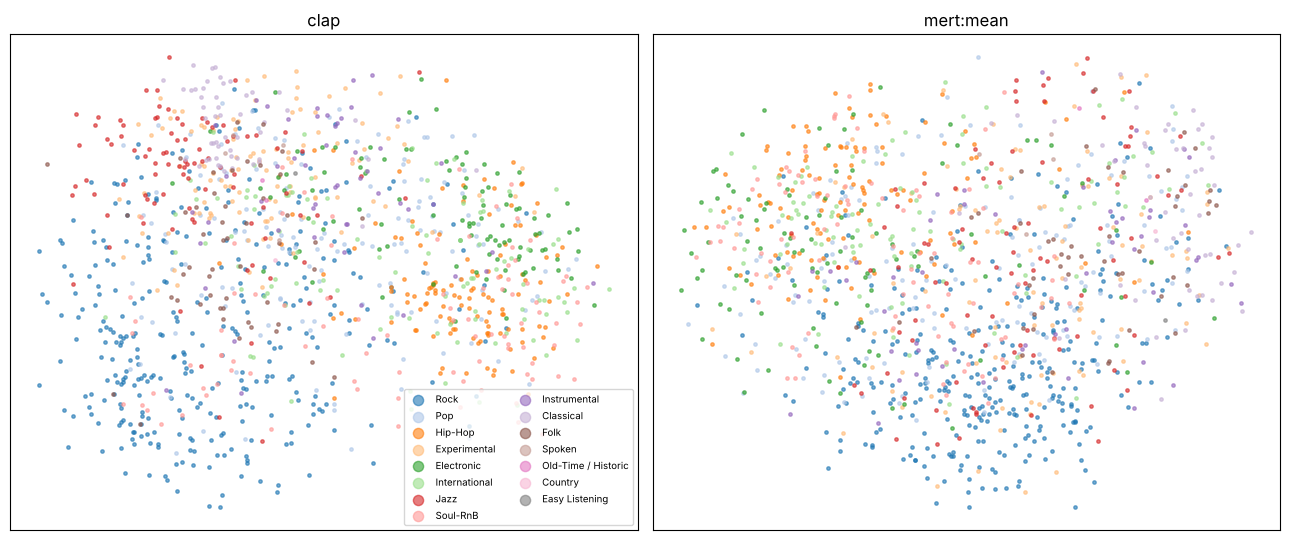

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, view in zip(axes, ["clap", "mert:mean"]):
    try:
        ids, X = load_view(cfg.embeddings_dir, view, cat.ids)
    except Exception as e:
        ax.set_title(f"{view}: {e}"); continue
    Z = PCA(2, random_state=0).fit_transform(X)
    genre = cat.tracks.loc[ids, "genre_hint"].fillna("unknown")
    for j, gname in enumerate(genre.value_counts().index[:16]):
        m = (genre == gname).values
        ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.6, label=gname, color=plt.cm.tab20(j))
    ax.set_title(view); ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=7, ncol=2)
plt.tight_layout()

## 2. Embedding comparison (from `scripts/compare_embeddings.py`)

In [3]:
p = REPO_ROOT / "reports" / "embedding_comparison.md"
display(Markdown(p.read_text() if p.exists() else "Run scripts/compare_embeddings.py first."))

# Embedding comparison: CLAP vs MERT on FMA

Sample: 440 FMA clips (30 s), 11 top-level genres, stratified (~40/genre). Same three 10 s windows per clip for both models, and the per-track vector is the mean over windows. Metrics are computed on centered + L2-normalised vectors.

## Full sample (all views)

| name            |   probe_macro_f1 |   knn_p@10 |   knn_acc |   subgenre_jaccard@10 |   anisotropy_raw |     dim |
|:----------------|-----------------:|-----------:|----------:|----------------------:|-----------------:|--------:|
| random (chance) |            0.091 |      0.085 |     0.105 |                 0.049 |          nan     | nan     |
| clap            |            0.535 |      0.445 |     0.586 |                 0.305 |            0.198 | 512.000 |
| mert_L0         |            0.350 |      0.229 |     0.343 |                 0.153 |            0.850 | 768.000 |
| mert_L1         |            0.386 |      0.237 |     0.350 |                 0.163 |            0.779 | 768.000 |
| mert_L2         |            0.405 |      0.252 |     0.405 |                 0.172 |            0.752 | 768.000 |
| mert_L3         |            0.454 |      0.271 |     0.380 |                 0.187 |            0.761 | 768.000 |
| mert_L4         |            0.480 |      0.285 |     0.402 |                 0.196 |            0.765 | 768.000 |
| mert_L5         |            0.499 |      0.298 |     0.402 |                 0.207 |            0.770 | 768.000 |
| mert_L6         |            0.509 |      0.307 |     0.427 |                 0.211 |            0.783 | 768.000 |
| mert_L7         |            0.491 |      0.303 |     0.398 |                 0.210 |            0.777 | 768.000 |
| mert_L8         |            0.479 |      0.307 |     0.420 |                 0.210 |            0.799 | 768.000 |
| mert_L9         |            0.457 |      0.290 |     0.402 |                 0.197 |            0.801 | 768.000 |
| mert_L10        |            0.418 |      0.265 |     0.375 |                 0.177 |            0.795 | 768.000 |
| mert_L11        |            0.412 |      0.256 |     0.375 |                 0.173 |            0.726 | 768.000 |
| mert_L12        |            0.351 |      0.243 |     0.361 |                 0.162 |            0.804 | 768.000 |
| mert_mean_all   |            0.456 |      0.279 |     0.416 |                 0.191 |            0.805 | 768.000 |

## Held-out head-to-head (MERT layer chosen on half A by subgenre_jaccard@10, scored on half B, n=220)

| name         |   probe_macro_f1 |   knn_p@10 |   knn_acc |   subgenre_jaccard@10 |   anisotropy_raw |   dim |
|:-------------|-----------------:|-----------:|----------:|----------------------:|-----------------:|------:|
| clap         |            0.501 |      0.393 |     0.564 |                 0.243 |            0.204 |   512 |
| mert_L8      |            0.455 |      0.255 |     0.377 |                 0.163 |            0.795 |   768 |
| clap+mert_L8 |            0.493 |      0.372 |     0.550 |                 0.232 |           -0.001 |  1280 |

Selected MERT view: **mert_L8** (use view name `mert:L8`).

## Cost (cpu, 4 threads, this dev container; `scripts/bench_embed.py`)

* clap: 0.44 s/track model + 0.17 s decode (3 x 10 s windows)
* mert: 2.12 s/track model + 0.16 s decode (3 x 10 s windows)


## 3. Your taste modes
Liked tracks are clustered, and each mode is listed with the tracks closest to its centre.
If two modes look like the same thing to you, that's fine: the model doesn't need them to
be "genres".

In [4]:
from rezonate.taste.knn import KNNTaste
rows = labels.track_id.map(cat.row).values
knn = KNNTaste().fit(cat.X[rows], labels.grade.values)
modes = knn.modes()
for i, c in enumerate(modes):
    near = np.argsort(-(cat.X @ c))[:5]
    t = cat.tracks.iloc[near][["artist", "title", "genre_hint"]]
    display(Markdown(f"**Mode {i + 1}**")); display(t)

**Mode 1**

,artist,title,genre_hint
track_id,,,
fma:137837,Long Beard,Summer/Fall,Rock
fma:129867,Expert Alterations,Psychic Surgery,Rock
fma:734,Glass Candy,Crystal Migraine,Soul-RnB
fma:85698,Souvenir Driver,F is For Fake,Rock
fma:760,Glass Candy,Empty V,Soul-RnB


**Mode 2**

,artist,title,genre_hint
track_id,,,
fma:113353,Chicano Batman,La Tigresa,Soul-RnB
fma:113347,Chicano Batman,El Frio,Soul-RnB
fma:113350,Chicano Batman,It's a Balloon,Soul-RnB
fma:113349,Chicano Batman,La Samoana,Soul-RnB
fma:113355,Chicano Batman,Soniatl,Soul-RnB


**Mode 3**

,artist,title,genre_hint
track_id,,,
fma:41378,Phemale,PUKE,Pop
fma:41386,Phemale,BETAWAVEBOY,Pop
fma:41819,Phemale,A SAD KID,Pop
fma:42915,Phemale,FACE FARM,Pop
fma:88429,Human Resources,Stinger Sisters,Pop


... (6 outputs left out)

**Mode 7**

,artist,title,genre_hint
track_id,,,
fma:18817,Gabe Noel,About You,Jazz
fma:62852,Yoni Kretzmer 2Bass Quartet,Giving Tree,Jazz
fma:51931,The Chris Kelsey 4,Ghosts,Jazz
fma:32892,Hargreaves / Noyes / Duplant,oublier que le temps passe,Jazz
fma:54268,Assif Tsahar And The Zoanthropic Orchestra,"Embracing The Void, Pt. 3 - March 1982",Jazz


**Mode 8**

,artist,title,genre_hint
track_id,,,
fma:126661,Deaf Wish,Pain,Rock
fma:18584,Dragon Or Emperor,Part of Me Says,Rock
fma:137739,Rye Coalition,White Jesus of 114th St,Rock
fma:51359,Sometimes Always,Old-Fashioned Baby,Rock
fma:26728,DUSTdevils,Receiver,Rock


## 4. A recommendation batch, with audio

In [5]:
model = service.fit_bayes(cat, labels)
picks = service.recommend(cat, model, labels, n=10, eps=cfg.explore_fraction, seed=1)
batch = pd.DataFrame([{**cat.tracks.iloc[p.row][["artist", "title", "source", "license"]].to_dict(),
                       "context": p.context, "why": p.reason, "track_id": cat.ids[p.row]}
                      for p in picks])
display(batch)
for p in picks[:3]:
    r = cat.tracks.iloc[p.row]
    display(Markdown(f"{r.artist} — {r.title} *({p.context})*"))
    display(Audio(r.audio_path))

,artist,title,source,license,context,why,track_id
0,Party Boys,Mr White,fma,Attribution-Noncommercial-No Derivative Works ...,exploit,score 0.70,fma:34578
1,TransFX,Fugue 7,fma,Creative Commons Attribution-NonCommercial-NoD...,exploit,score 0.70,fma:130371
2,Long Beard,Summer/Fall,fma,Creative Commons Attribution-NonCommercial-NoD...,exploit,score 0.66,fma:137837
3,Garmisch,Facing the Sea,fma,Attribution-NonCommercial-NoDerivatives (aka M...,explore,"unfamiliar region (cluster 22, 7% rated)",fma:35544
4,Garmisch,Laugh Tracks,fma,Attribution-NonCommercial-NoDerivatives (aka M...,exploit,score 0.70,fma:35549
5,Juanitos,Funkula,fma,Attribution 2.0 France,exploit,score 0.73,fma:23178
6,King Ghidorah!,pentacle blues,fma,Attribution-NonCommercial-NoDerivatives (aka M...,exploit,score 0.68,fma:62522
7,Hypnobeat,Spies In Malaysia,fma,Attribution-NonCommercial,exploit,score 0.70,fma:120102
8,Dumbo Gets Mad,Raymond Play,fma,Attribution-NonCommercial-ShareAlike 3.0 Inter...,exploit,score 0.71,fma:47923
9,Phemale,skinn,fma,Attribution-Noncommercial-Share Alike 3.0 Unit...,explore,"unfamiliar region (cluster 9, 5% rated)",fma:51286


Party Boys — Mr White *(exploit)*

[audio player stripped from committed notebook]


TransFX — Fugue 7 *(exploit)*

[audio player stripped from committed notebook]


Long Beard — Summer/Fall *(exploit)*

[audio player stripped from committed notebook]


## 5. Rate from the notebook
`rate(i, grade)` uses the batch index above and grades 0 = dislike, 1 = meh, 2 = like,
3 = love. In demo mode nothing is written.

In [6]:
def rate(i, grade):
    p = picks[i]
    if DEMO and (labels.label_source == "simulated").all():
        print("demo mode: not saved"); return
    db.add_feedback(con, [(cat.ids[p.row], grade, "notebook", p.context)])
    model.update(cat.X[p.row], grade)
    print("saved; P(like) now", float(model.score(cat.X[[p.row]])[0]))

# rate(0, 3)

## 6. Offline evaluation reports

In [7]:
for name in ["eval_simulated.md", "exploration_simulated.md"]:
    p = REPO_ROOT / "reports" / name
    if p.exists():
        display(Markdown(p.read_text()))

# Offline evaluation on a SIMULATED listener (FMA)

> These numbers validate the pipeline. They are **not** evidence about your taste: the
> listener is simulated from FMA genre labels (see `src/rezonate/eval/simulate.py`).
> Re-run `rezonate evaluate` on your own ratings before trusting any conclusion.

* catalogue: 1240 FMA tracks; each persona rates 300 random tracks
* persona taste modes: post-punk / garage, indie / lo-fi / shoegaze, alt / synth pop, soul / r&b, reggae / dub, jazz-punk / free jazz, heavy alt rock
* protocol: 5-fold x 2 repeats x 3 personas = 30 folds per model; NDCG@10 on held-out rated tracks (gain 2^grade - 1); 95 % bootstrap CI
* `top10_pop_pct`: mean popularity percentile of each model's top 10 (lower = more niche picks)
* context coverage on this sample: tags 47%, era 100%, lyrics 1.7% (LRCLIB rarely knows FMA artists)

## Taste models vs baselines (audio only)

| model                 |   ndcg@10 | ndcg@10_ci     |   ndcg@5 |   p@10(like+) |   top10_pop_pct |
|:----------------------|----------:|:---------------|---------:|--------------:|----------------:|
| knn | clap+mert:L8    |     0.491 | [0.455, 0.528] |    0.489 |         0.603 |           0.473 |
| knn | clap            |     0.488 | [0.447, 0.532] |    0.478 |         0.617 |           0.483 |
| bayes | clap          |     0.481 | [0.443, 0.518] |    0.498 |         0.570 |           0.503 |
| ranker | clap         |     0.473 | [0.427, 0.518] |    0.456 |         0.587 |           0.511 |
| ranker | clap+mert:L8 |     0.466 | [0.430, 0.503] |    0.453 |         0.580 |           0.507 |
| bayes | clap+mert:L8  |     0.449 | [0.407, 0.491] |    0.455 |         0.547 |           0.484 |
| bayes | mert:L8       |     0.438 | [0.407, 0.468] |    0.446 |         0.517 |           0.468 |
| ranker | mert:L8      |     0.419 | [0.385, 0.450] |    0.420 |         0.507 |           0.476 |
| popularity            |     0.417 | [0.359, 0.470] |    0.442 |         0.450 |           0.920 |
| knn | mert:L8         |     0.406 | [0.367, 0.446] |    0.431 |         0.490 |           0.454 |
| random                |     0.265 | [0.226, 0.304] |    0.234 |         0.340 |           0.497 |

## Context-feature ablation (CLAP audio + context)

| model                         |   ndcg@10 | ndcg@10_ci     |   ndcg@5 |   p@10(like+) |   top10_pop_pct |
|:------------------------------|----------:|:---------------|---------:|--------------:|----------------:|
| ranker | clap+tags            |     0.554 | [0.513, 0.591] |    0.615 |         0.633 |           0.560 |
| bayes | clap+tags+era+lyrics  |     0.546 | [0.508, 0.580] |    0.581 |         0.630 |           0.553 |
| ranker | clap+tags+era+lyrics |     0.546 | [0.505, 0.585] |    0.591 |         0.633 |           0.543 |
| bayes | clap+tags             |     0.545 | [0.508, 0.578] |    0.591 |         0.613 |           0.561 |
| bayes | clap+pop              |     0.538 | [0.493, 0.578] |    0.574 |         0.617 |           0.673 |
| ranker | clap+pop             |     0.513 | [0.467, 0.558] |    0.528 |         0.610 |           0.603 |
| bayes | clap                  |     0.481 | [0.443, 0.518] |    0.498 |         0.570 |           0.503 |
| ranker | clap+era             |     0.475 | [0.432, 0.517] |    0.463 |         0.600 |           0.503 |
| bayes | clap+lyrics           |     0.475 | [0.435, 0.513] |    0.497 |         0.553 |           0.500 |
| ranker | clap                 |     0.473 | [0.427, 0.518] |    0.456 |         0.587 |           0.511 |
| ranker | clap+lyrics          |     0.473 | [0.424, 0.519] |    0.456 |         0.590 |           0.511 |
| bayes | clap+era              |     0.471 | [0.429, 0.511] |    0.484 |         0.573 |           0.505 |

## Paired differences (same folds; more sensitive than comparing the CIs above)

| comparison                                            |   mean Δ | 95% CI           | folds won   |
|:------------------------------------------------------|---------:|:-----------------|:------------|
| knn | clap  vs  popularity                            |   +0.072 | [-0.006, +0.154] | 18/30       |
| bayes | clap  vs  popularity                          |   +0.065 | [-0.008, +0.141] | 17/30       |
| ranker | clap  vs  popularity                         |   +0.057 | [-0.025, +0.140] | 18/30       |
| knn | clap  vs  knn | mert:L8                         |   +0.082 | [+0.045, +0.123] | 23/30       |
| bayes | clap  vs  knn | clap                          |   -0.007 | [-0.046, +0.035] | 15/30       |
| ranker | clap  vs  knn | clap                         |   -0.015 | [-0.045, +0.018] | 12/30       |
| ranker | clap+tags  vs  ranker | clap                 |   +0.081 | [+0.044, +0.118] | 25/30       |
| bayes | clap+tags  vs  bayes | clap                   |   +0.064 | [+0.025, +0.099] | 22/30       |
| ranker | clap+era  vs  ranker | clap                  |   +0.002 | [-0.014, +0.018] | 12/30       |
| ranker | clap+lyrics  vs  ranker | clap               |   -0.000 | [-0.010, +0.009] | 11/30       |
| bayes | clap+pop  vs  bayes | clap                    |   +0.057 | [+0.026, +0.089] | 23/30       |
| ranker | clap+tags+era+lyrics  vs  ranker | clap+tags |   -0.008 | [-0.025, +0.008] | 15/30       |


# Exploration: online simulation (SIMULATED listener, CLAP view)

Start: 30 ratings drawn only from 2 of 7 taste modes. 10 rounds x 20 recommendations.
Means over 8 seeds (per-seed rows in the CSV).
*Full pool*: the 1,240-track sample, in which liked music is common (the sample oversamples taste sub-genres). *Rare*: every non-starting mode is cut to 12 tracks, the niche case this project is for.

| scenario       |   eps |   hit_rate |   explore_hit_rate |   modes_found |   new_modes_by_round3 |   rounds_to_new_mode |   catalogue_ndcg@50 |
|:---------------|------:|-----------:|-------------------:|--------------:|----------------------:|---------------------:|--------------------:|
| full pool      |  0.00 |       0.52 |             nan    |          6.50 |                  0.70 |                 3.45 |                0.43 |
| full pool      |  0.25 |       0.49 |               0.34 |          7.00 |                  0.88 |                 2.00 |                0.46 |
| full pool      |  0.50 |       0.45 |               0.33 |          7.00 |                  0.93 |                 1.78 |                0.42 |
| rare (12/mode) |  0.00 |       0.67 |             nan    |          5.75 |                  0.28 |                 6.72 |                0.39 |
| rare (12/mode) |  0.25 |       0.59 |               0.27 |          6.00 |                  0.43 |                 5.38 |                0.52 |
| rare (12/mode) |  0.50 |       0.48 |               0.27 |          6.50 |                  0.50 |                 4.88 |                0.53 |

* `hit_rate`: share of recommended tracks the listener likes. Exploration costs some of this in the short run.
* `modes_found`: taste modes (of 7) with at least one recommended like. Includes the 2 starting modes.
* `explore_hit_rate`: like rate of the exploration slots alone.
* `new_modes_by_round3`: share of the 5 non-starting modes liked within 3 batches.
* `rounds_to_new_mode`: mean batch index at which a non-starting mode is first liked (11 = not found within 10 batches). Lower = faster discovery.
* `catalogue_ndcg@50`: final model's ranking of every still-unrated track.
